Ячейка 1 (Загрузка):

In [1]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.features import tokens, build_vocab, word_share_over_time, get_tfidf_top_words

df = pd.read_parquet('../data/processed/cleanfull.parquet')
print("Данные загружены")

Данные загружены


Ячейка 2 (Частотный словарь):

In [2]:
freq, pairs = build_vocab(df['callsign'])

print("Топ-10 слов:")
print(freq.most_common(10))

print("\nТоп-10 биграмм:")
print(pairs.most_common(10))

Топ-10 слов:
[('SWA', 366324), ('AAL', 297274), ('UAL', 227817), ('DAL', 213789), ('RYR', 206517), ('DLH', 166604), ('SKW', 140116), ('EZY', 132820), ('BAW', 94750), ('AFR', 83226)]

Топ-10 биграмм:
[(('IBE', '31'), 7029), (('IBE', '32'), 5316), (('IBE', '34'), 2662), (('EZY', '71'), 2127), (('EZY', '74'), 2093), (('EZY', '37'), 2084), (('EZY', '63'), 2019), (('EZY', '58'), 2005), (('EZY', '72'), 1999), (('EZY', '38'), 1963)]


Ячейка 3 (Динамика долей):

Выбранные слова: ['SWA', 'AAL', 'UAL', 'DAL', 'RYR']


c:\Users\Jesayz\LaboratoryOne\notebooks\..\src\features.py:38: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_temp["period"] = df_temp[date_col].dt.to_period("M")


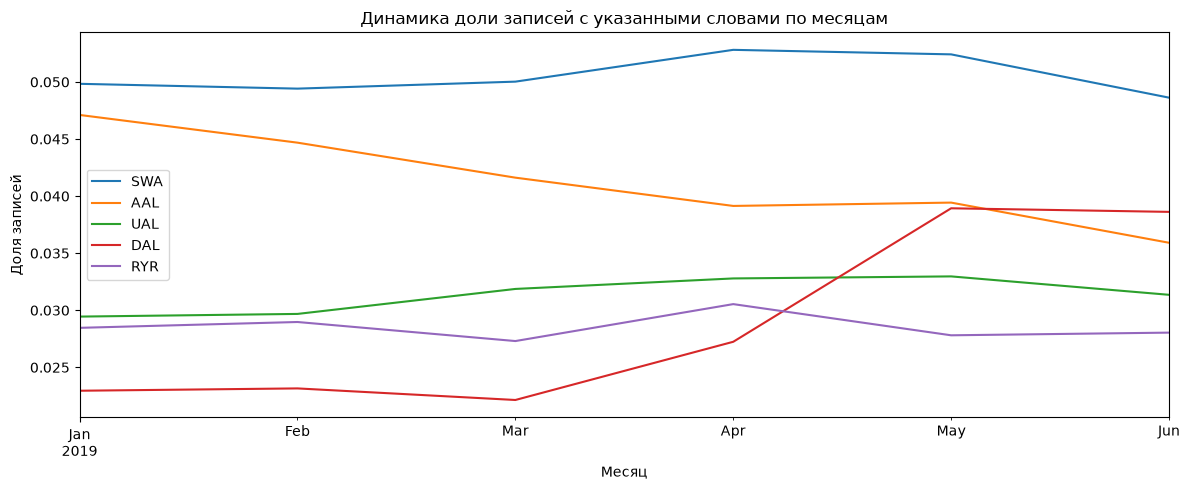

In [3]:
# Берем 5 частых слов (например, коды авиакомпаний)
top_words = [word for word, count in freq.most_common(5)]
print(f"Выбранные слова: {top_words}")

# Считаем динамику
shares_df = word_share_over_time(df, top_words, date_col='day')

# Строим график
shares_df.plot(figsize=(12, 5))
plt.title('Динамика доли записей с указанными словами по месяцам')
plt.ylabel('Доля записей')
plt.xlabel('Месяц')
plt.tight_layout()
plt.savefig('../plots/14_word_shares.png', dpi=150)
plt.show()

Ячейка 4 (TF-IDF):

In [4]:
# Ищем характерные слова для аэропортов (возьмем 3 топ-аэропорта)
top_airports = ['KORD', 'KLAX', 'EGLL']
results = get_tfidf_top_words(df[df['origin'].isin(top_airports)], 'callsign', 'origin', top_n=5)

print("Характерные слова по аэропортам (TF-IDF):")
for airport, words in results.items():
    print(f"{airport}: {words}")

Характерные слова по аэропортам (TF-IDF):
KLAX: ['cpz6089', 'aca792', 'cpz6095', 'jbu2024', 'aal2543']
KORD: ['ual845', 'nks357', 'ual944', 'ual1742', 'nks224']
EGLL: ['vir7b', 'baw7w', 'baw91c', 'aal105', 'aal79']


### Таблица 6 - Частые слова и биграммы

| Ранг | Слово | Частота | Биграмма | Частота |
| :--- | :--- | :--- | :--- | :--- |
| 1 | SWA | 366 324 | IBE 31 | 7 029 |
| 2 | AAL | 297 274 | IBE 32 | 5 316 |
| 3 | UAL | 227 817 | IBE 34 | 2 662 |
| 4 | DAL | 213 789 | EZY 71 | 2 127 |
| 5 | RYR | 206 517 | EZY 74 | 2 093 |

**Вывод по текстовым признакам:**

В ходе анализа текстового столбца `callsign` был построен частотный словарь. Самыми частыми токенами (аналогами слов) стали коды авиакомпаний: SWA (Southwest Airlines), AAL (American Airlines), UAL (United Airlines), DAL (Delta Air Lines) и RYR (Ryanair). Это крупнейшие перевозчики, представленные в наборе.

Анализ биграмм (пар токенов) выявил устойчивые сочетания, представляющие собой префикс авиакомпании и номер рейса: IBE 31, IBE 32, EZY 71. Это подтверждает, что позывные состоят из буквенного кода перевозчика и цифрового идентификатора рейса.

При построении динамики по месяцам (график) видно, что доля записей авиакомпании SWA стабильно высока (около 5%), в то время как у Delta (DAL) наблюдается резкий рост доли с марта по апрель 2019 года (с 2.3% до 4%). 

С помощью TF-IDF были найдены характерные слова для топ-3 аэропортов. Для KLAX (Лос-Анджелес) характерны рейсы компаний CPZ (Compass Airlines) и ACA (Air Canada); для KORD (Чикаго) — UAL (United Airlines) и NKS (Spirit Airlines); для EGLL (Лондон) — VIR (Virgin Atlantic) и BAW (British Airways). Это наглядно показывает, какие авиакомпании доминируют в каждом хабе.

### Таблица 7 - Состав витрины

| Источник | Колонок | Примеры | Отброшено при отборе |
| :--- | :--- | :--- | :--- |
| Категории | 2 | origin_freq, typecode_freq | — |
| Дата | 4 | month, day_of_week, is_weekend | year (почти постоянный) |
| Агрегаты по группе | 3 | origin_count, origin_median_alt | — |
| Текст | 4 | callsign_len, airline_freq, airline_prefix_len | — |
| Исходные числовые | 7 | latitude_1, longitude_1, altitude_1, ... | — |
| **Итого** | **20** | | 1 |